# Reading the scraped data from the database

In [2]:
import src.Feature_finder as ff
import pandas as pd

words = ff.load_database("src/data/connections.db")

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
print("Words: ")
print(words.head())

Words: 
  puzzle_date  puzzle_number  difficulty   color     category  position   word
0  2023-06-12              1         NaN  yellow  WET WEATHER         1   HAIL
1  2023-06-12              1         NaN  yellow  WET WEATHER         2   RAIN
2  2023-06-12              1         NaN  yellow  WET WEATHER         3  SLEET
3  2023-06-12              1         NaN  yellow  WET WEATHER         4   SNOW
4  2023-06-12              1         NaN   green    NBA TEAMS         1  BUCKS


# Finding the length of the words in the database

# encoding the color as a group difficulty

In [2]:
# 1. Load & clean
words = ff.load_database("data/connections.db")
words = ff.clean_encode(words)
words = ff.add_scrabble_score(words)

# 2. Add embeddings (once)
words, emb_dict = ff.add_embeddings(words)

# 3. Group-level features (now includes semantic similarity)
group_features = ff.get_group_features(words, emb_dict=emb_dict)

# 4. Puzzle-level features (can also pull the semantic aggregates)
puzzle_features = ff.get_puzzle_features(words, group_features=group_features)

print(group_features.head())
print(puzzle_features.head())


Batches: 100%|██████████| 276/276 [01:16<00:00,  3.60it/s]


  puzzle_date       category  difficulty  mean_scrabble  max_scrabble  min_scrabble  sd_scrabble  mean_scrabble_per_letter  mean_word_length  max_word_length  sd_word_length  mean_semantic_sim  min_semantic_sim  max_semantic_sim  std_semantic_sim
0  2023-06-12  KEYBOARD KEYS           3           7.50            11             5     2.645751                      1.55               5.0                6        1.414214           0.318733          0.221295          0.395129          0.053755
1  2023-06-12      NBA TEAMS           2          13.25            29             4    11.146748                      3.15              4.25                5             0.5           0.389485          0.344522          0.473444          0.046533
2  2023-06-12    PALINDROMES           4          10.50            16             7     4.041452                   2.17619               5.0                7        1.632993           0.280497          0.197382          0.385297          0.061834
3  2023-06-1

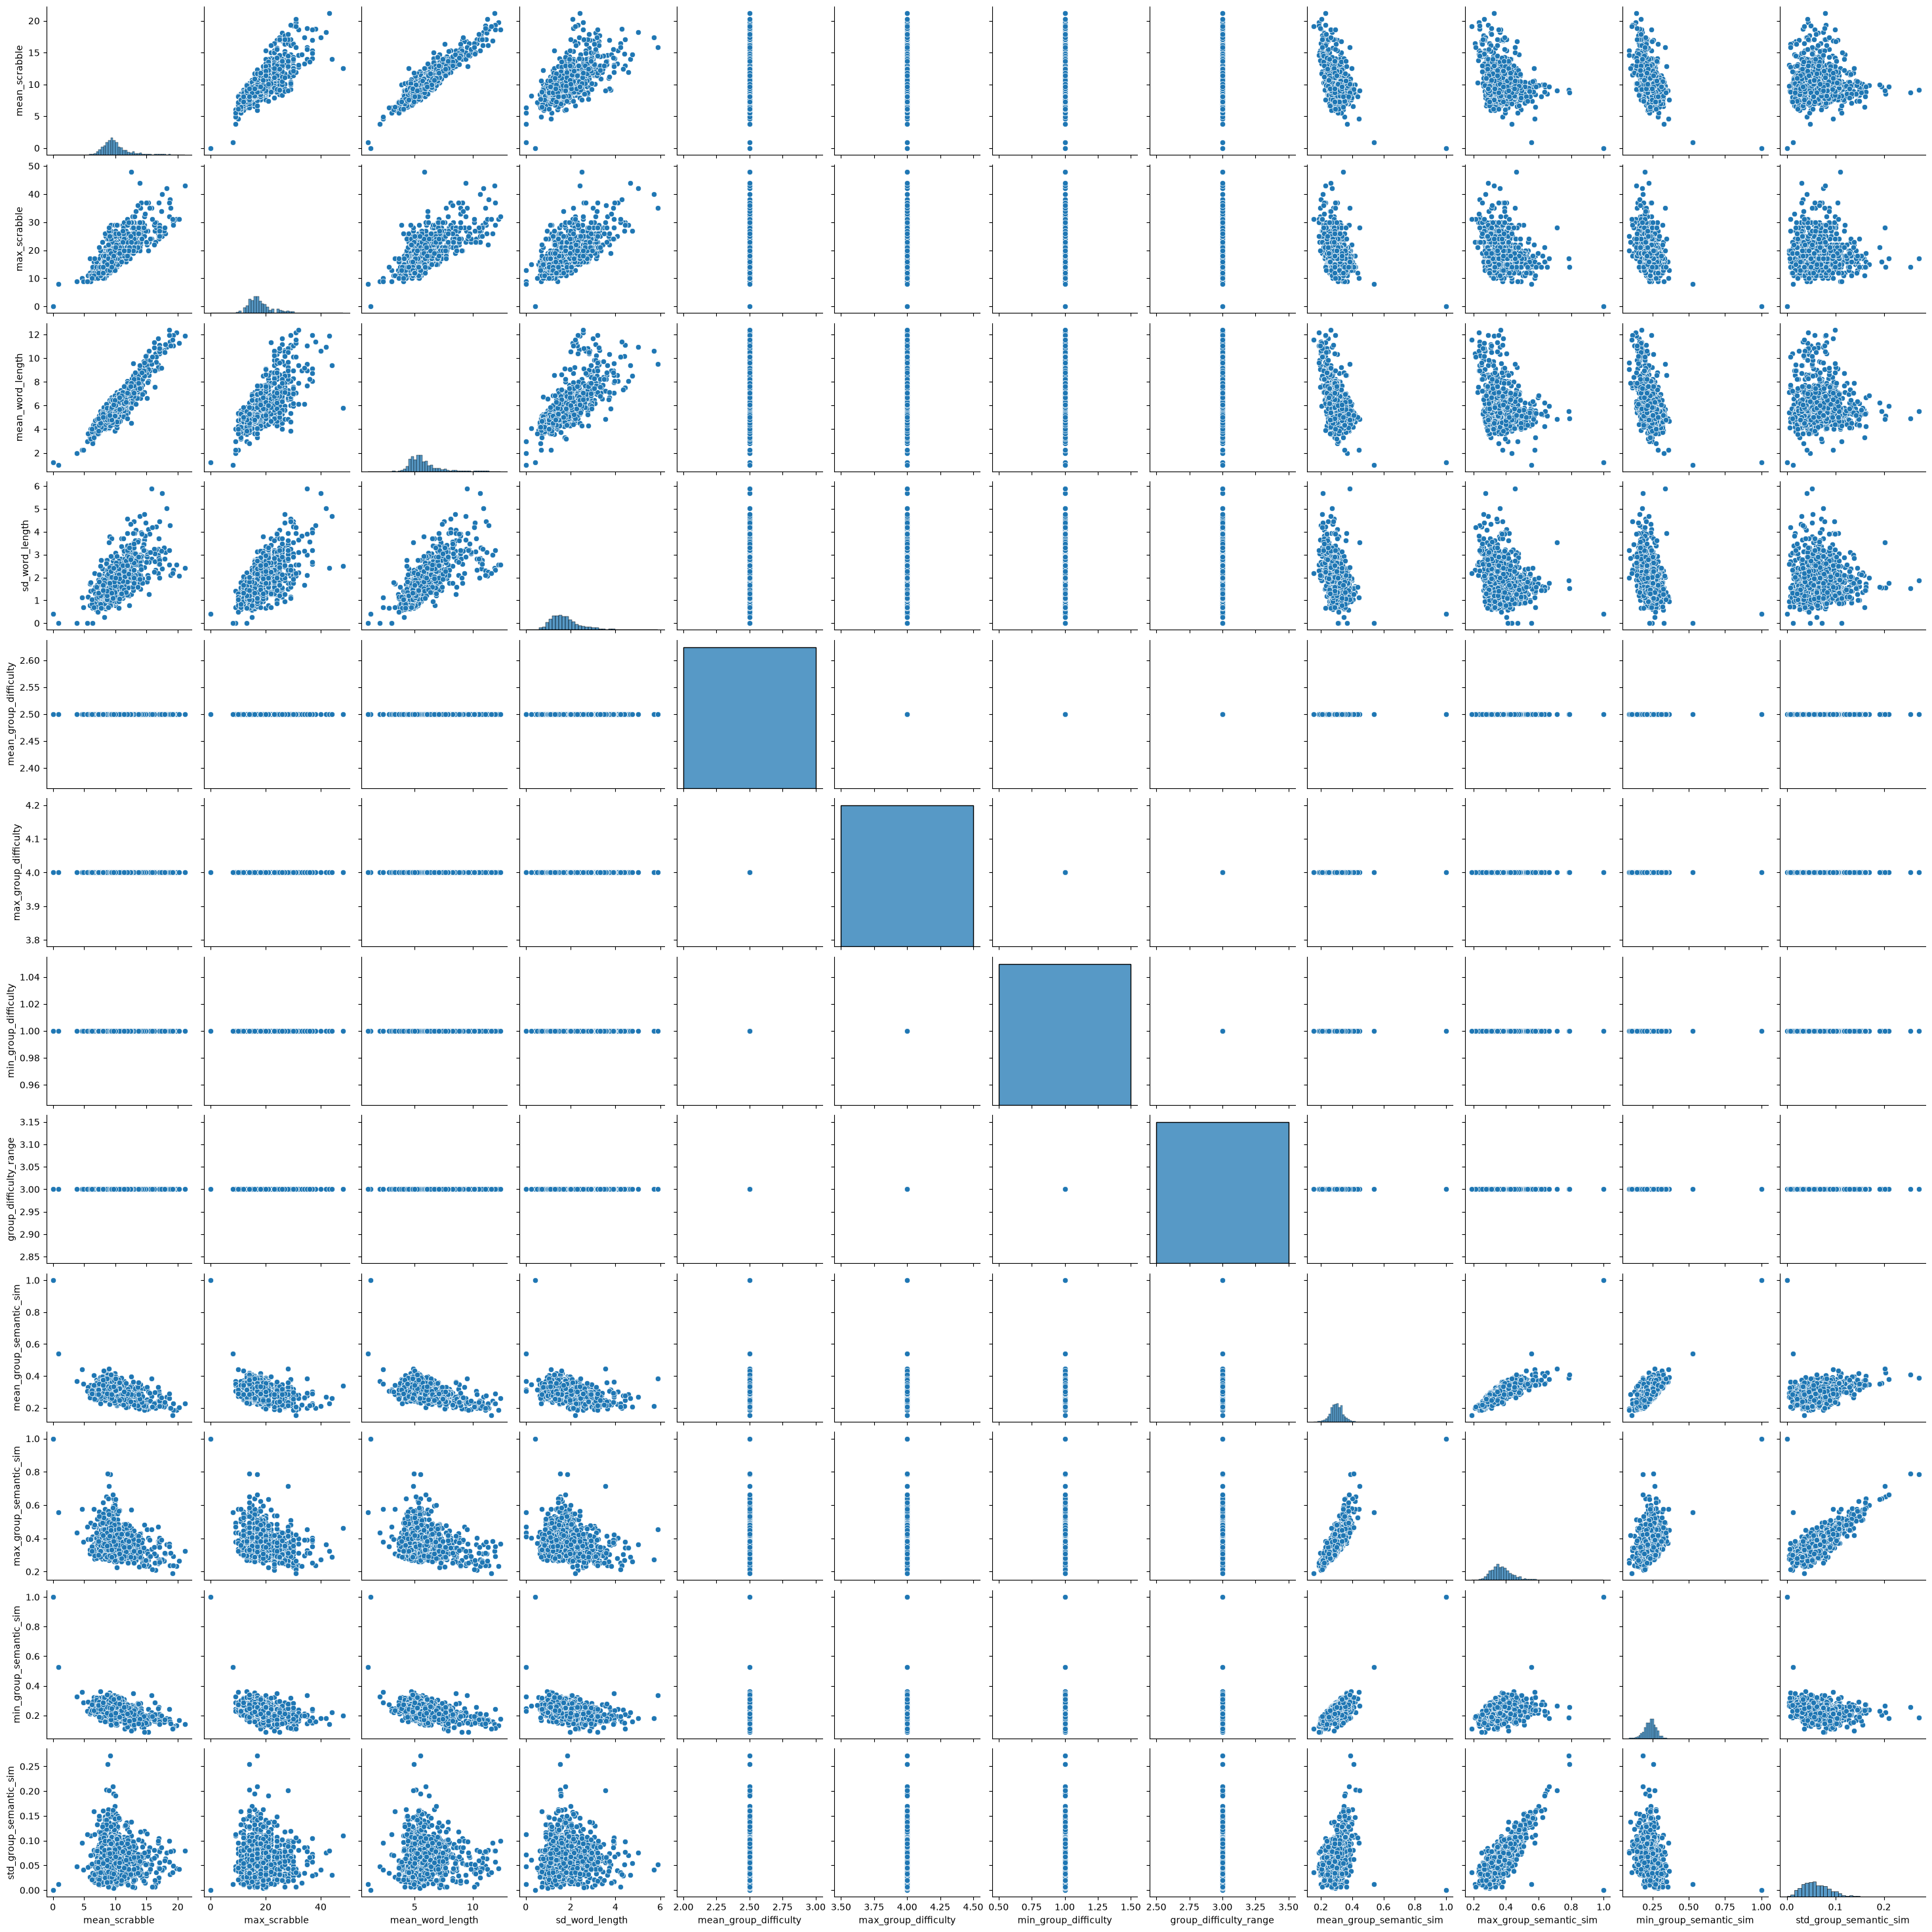

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.pairplot(puzzle_features)
plt.show()

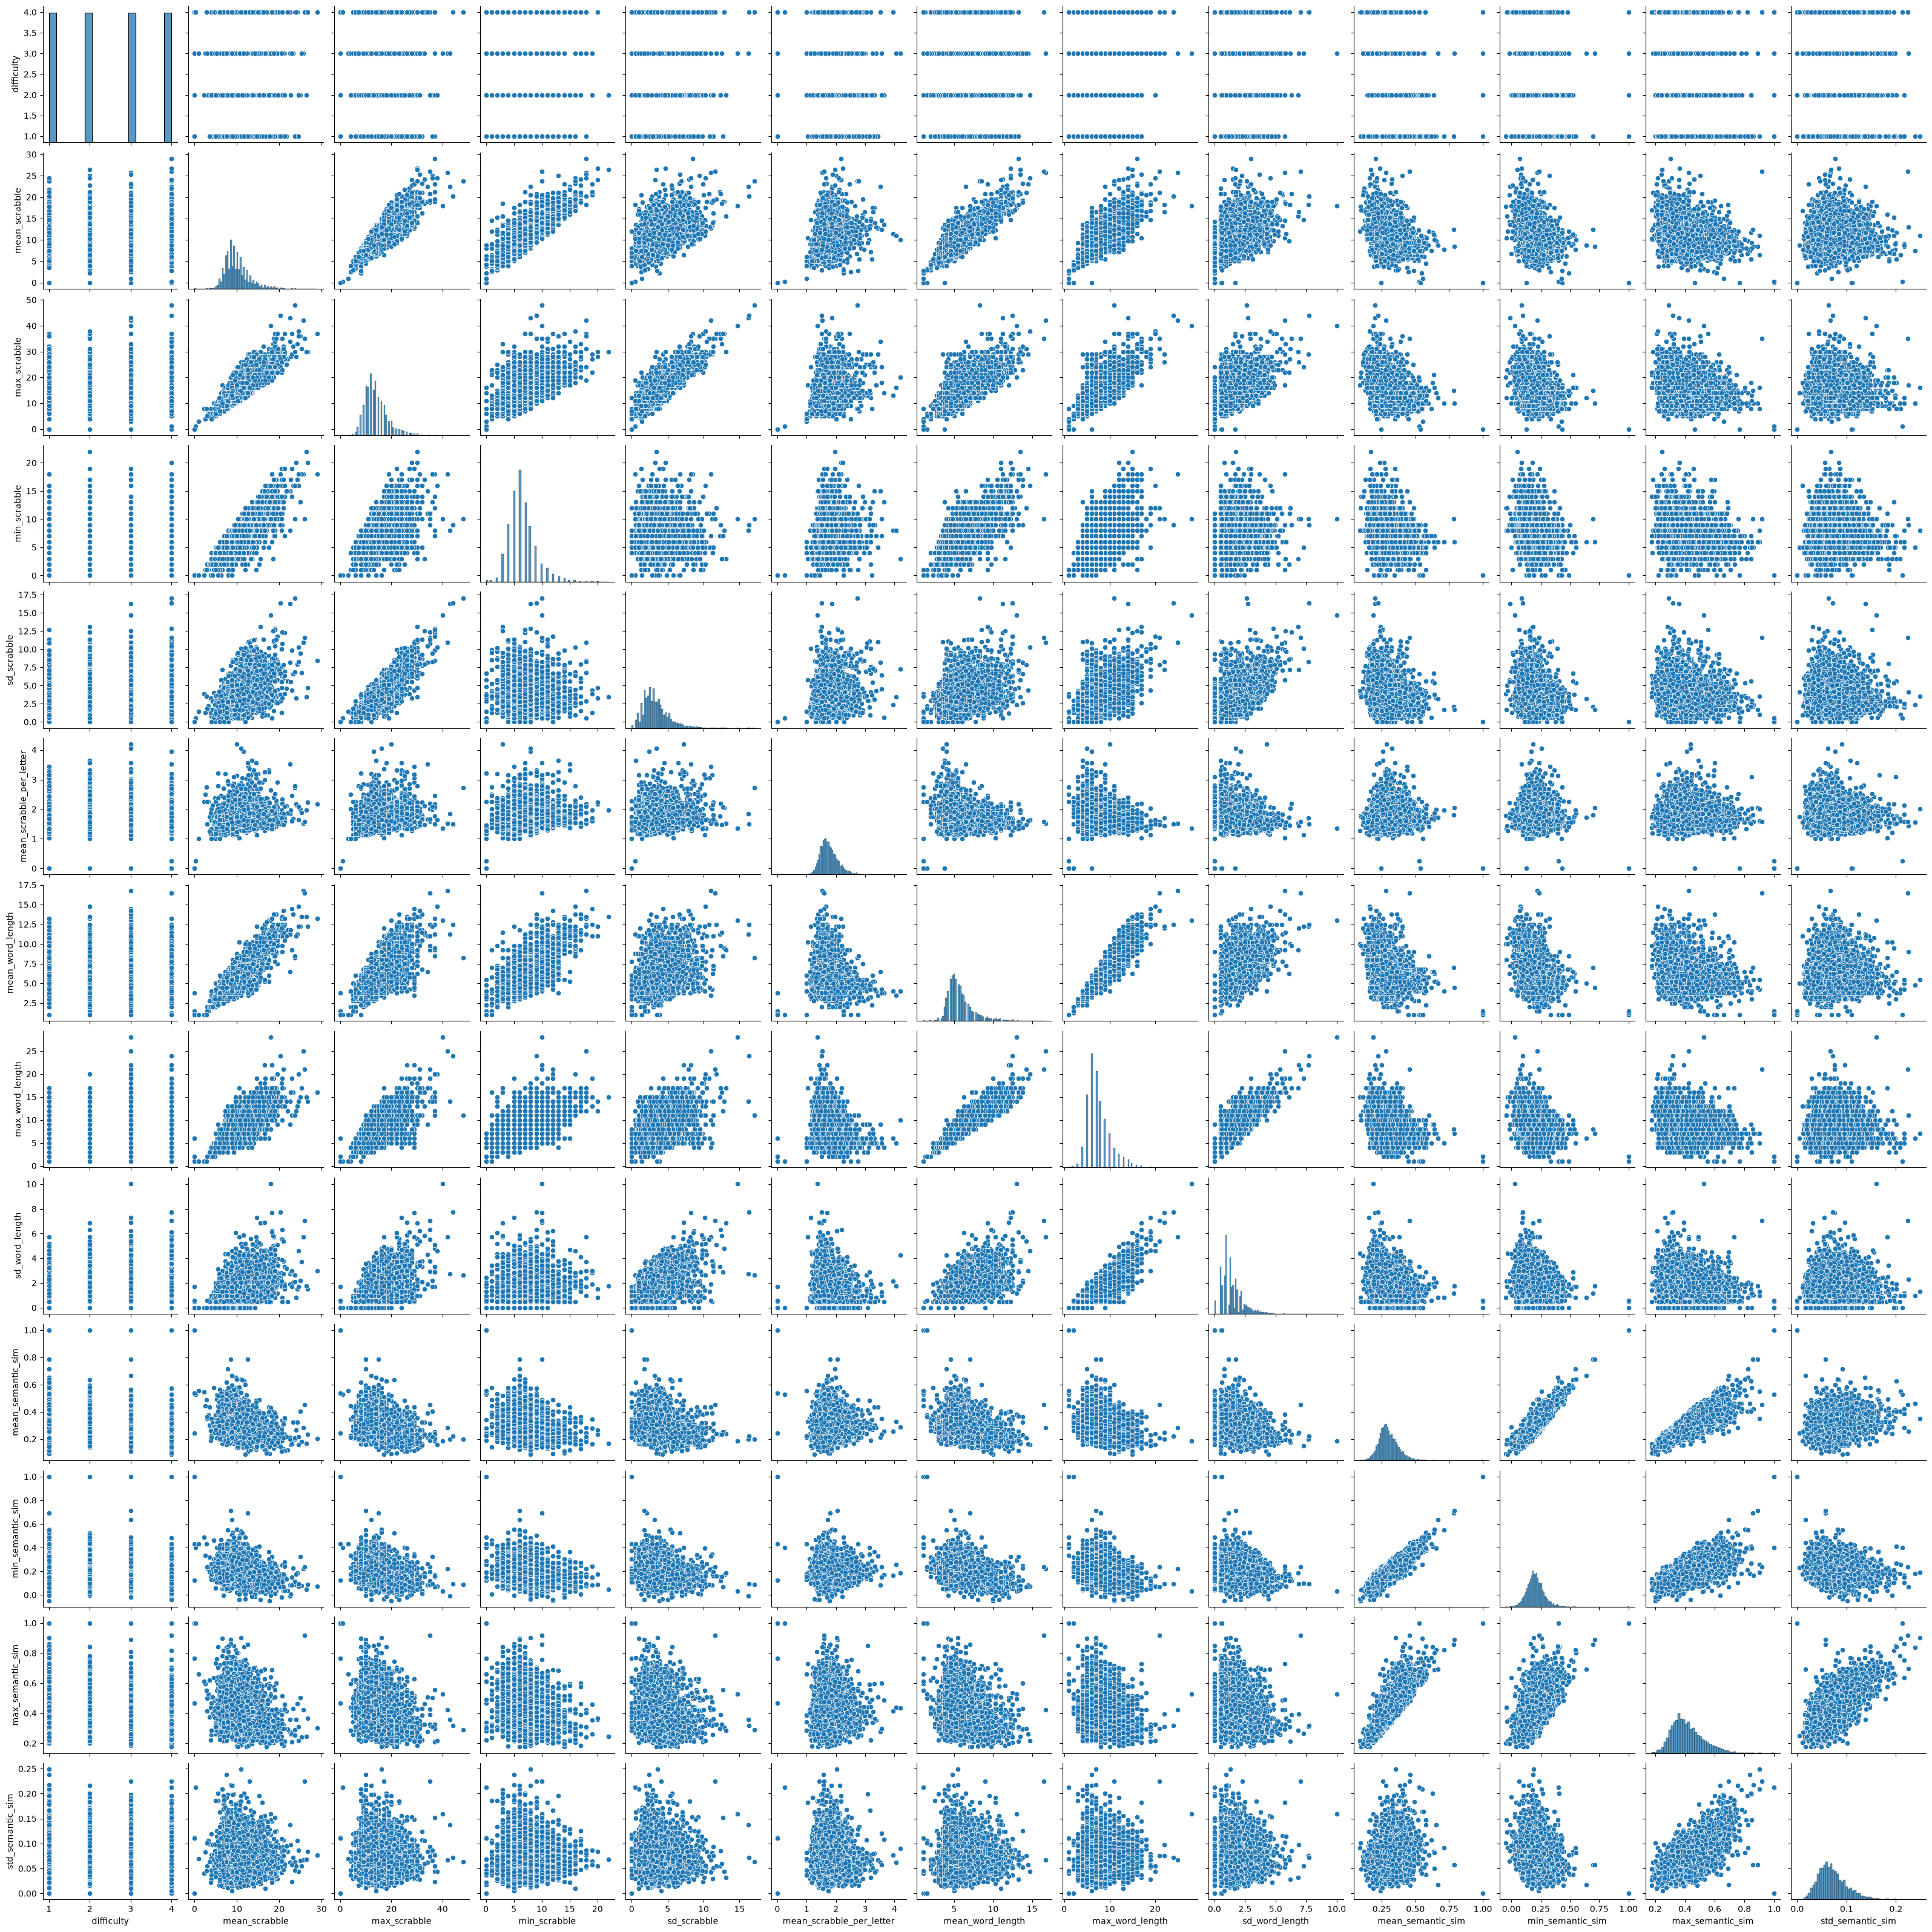

In [4]:
sns.pairplot(group_features)
plt.show()

In [5]:
sns.pairplot(words)
plt.show()

ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()